# Análise exploratória (EDA): temperatura no Brasil

Objetivo: entender os dados de clima antes de modelar a previsão de temperatura.

- Só **lê** o banco (`dados/warehouse.duckdb`): a camada **gold** criada pelo dbt (`gold.fct_clima_diario` e `gold.dim_municipio`).
- Antes: carga do clima (`python -m clima` ou notebook 02) e `dbt build` na pasta `dbt/`. A gold traz só dado fechado.
- Rode com a carga completa; com poucas cidades ou poucos anos, as conclusões enganam.

In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from clima.db import consultar

# Variáveis da camada gold (nomes e unidades definidos no dbt).
VARS = ["temp_media_c", "temp_max_c", "temp_min_c", "chuva_mm", "radiacao_mj_m2", "sol_horas", "vento_max_kmh"]

DB = Path("..") / "dados" / "warehouse.duckdb"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

# Camada gold (dbt): fato de clima + dimensão de municípios. Só dado fechado.
COM = """
with clima as (
    select f.*, d.nome_uf as nome, d.lat, d.lng
    from gold.fct_clima_diario f
    join gold.dim_municipio d using (ibge_id)
)
"""


def q(sql, params=None):
    """Consulta sobre a visão 'clima' (CTE acima) e devolve um DataFrame."""
    return consultar(COM + sql, DB, params)

## 1. Qualidade dos dados

In [14]:
display(q("""
    select count(*) as linhas, count(distinct ibge_id) as cidades,
           min(data) as de, max(data) as ate
    from clima
"""))

# Nulos por variável e dias faltando por cidade (buracos > 0 indicam falha na carga).
display(q("select " + ", ".join(f"count(*) - count({v}) as {v}" for v in VARS) + " from clima"))
display(q("""
    select nome, min(data) as de, max(data) as ate, count(*) as dias,
           (max(data) - min(data) + 1) - count(*) as buracos
    from clima group by nome order by buracos desc, nome
""").head(10))

,linhas,cidades,de,ate
0,197200,50,2016-01-01,2026-10-18


,temp_media_c,temp_max_c,temp_min_c,chuva_mm,radiacao_mj_m2,sol_horas,vento_max_kmh
0,0,0,0,0,0,0,0


,nome,de,ate,dias,buracos
0,Adamantina (SP),2016-01-01,2026-10-18,3944,0
1,Adolfo (SP),2016-01-01,2026-10-18,3944,0
2,Aguaí (SP),2016-01-01,2026-10-18,3944,0
3,Agudos (SP),2016-01-01,2026-10-18,3944,0
4,Alambari (SP),2016-01-01,2026-10-18,3944,0
5,Alfredo Marcondes (SP),2016-01-01,2026-10-18,3944,0
6,Altair (SP),2016-01-01,2026-10-18,3944,0
7,Altinópolis (SP),2016-01-01,2026-10-18,3944,0
8,Alto Alegre (SP),2016-01-01,2026-10-18,3944,0
9,Alumínio (SP),2016-01-01,2026-10-18,3944,0


In [15]:
# Carrega uma vez só; as próximas seções trabalham em memória.
# Calendário, amplitude e "ontem" já vêm prontos da gold.
df = q("select ibge_id, nome, uf_sigla, regiao_imediata, lat, lng, data, ano, mes, dia_do_ano, "
       "amplitude_c, temp_media_ontem_c, " + ", ".join(VARS) + " from clima")
assert not df.empty, "Gold vazia: rode a carga do clima e depois o dbt build."

df["data"] = pd.to_datetime(df["data"])
print(df.shape)

(197200, 19)


## 2. Distribuições

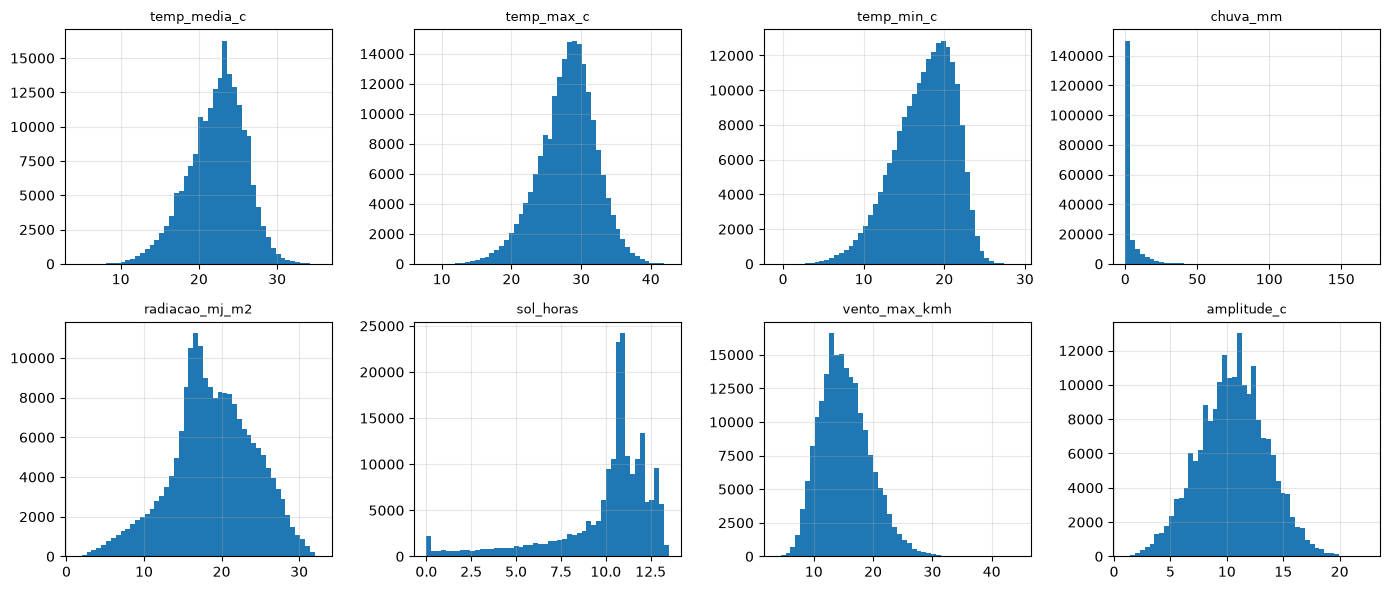

dias sem chuva: 47%


,count,mean,std,min,25%,50%,75%,max
temp_media_c,197200.0,22.265604,3.627097,4.40,20.000000,22.600000,24.800000,35.400000
temp_max_c,197200.0,28.055048,4.077493,7.80,25.600000,28.300000,30.700000,42.600000
temp_min_c,197200.0,17.506152,3.749080,-0.90,15.100000,18.000000,20.400000,29.200000
chuva_mm,197200.0,3.143682,6.635077,0.00,0.000000,0.100000,3.000000,168.500000
radiacao_mj_m2,197200.0,18.854293,5.352891,1.34,15.660000,18.740000,22.650000,32.610000
sol_horas,197200.0,10.029206,2.743216,0.00,9.598256,10.790197,11.700695,13.517003
vento_max_kmh,197200.0,15.275361,4.226839,3.60,12.200000,14.800000,17.900000,44.500000
amplitude_c,197200.0,10.548896,3.026181,1.00,8.500000,10.600000,12.600000,22.500000


In [16]:
cols = VARS + ["amplitude_c"]
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axes.ravel(), cols):
    ax.hist(df[c].dropna(), bins=50)
    ax.set_title(c, fontsize=9)
fig.tight_layout()
plt.show()

print(f"dias sem chuva: {(df['chuva_mm'] == 0).mean() * 100:.0f}%")
display(df[cols].describe().T)

## 3. Séries no tempo

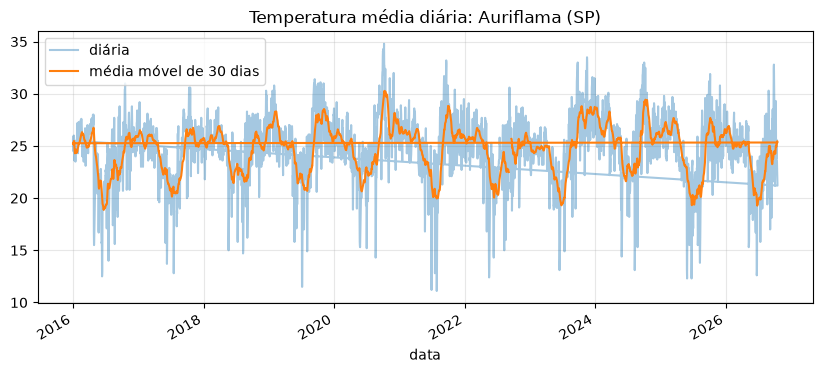

In [17]:
cidade = df["nome"].value_counts().index[0]   # cidade com mais dias; troque pelo nome que quiser
s = df[df["nome"] == cidade].set_index("data")["temp_media_c"]

fig, ax = plt.subplots()
s.plot(ax=ax, alpha=0.4, label="diária")
s.rolling(30, min_periods=15).mean().plot(ax=ax, label="média móvel de 30 dias")
ax.set_title(f"Temperatura média diária: {cidade}")
ax.legend()
plt.show()

,temp,dias
ano,,
2016,21.997426,366
2017,22.181238,365
2018,22.351962,365
2019,22.802647,365
2020,22.405661,366
2021,22.126997,365
2022,21.658822,365
2023,22.390838,365
2024,23.201393,366


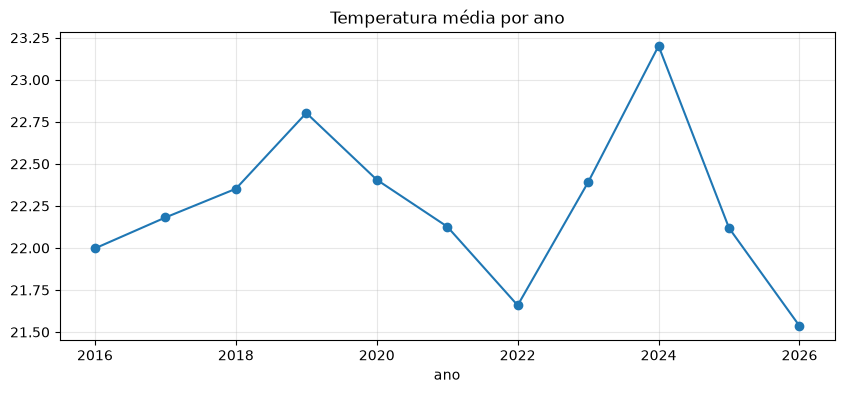

In [18]:
# Média por ano (anos incompletos distorcem: confira a coluna "dias").
anual = df.groupby("ano").agg(temp=("temp_media_c", "mean"), dias=("data", "nunique"))
display(anual)
fig, ax = plt.subplots()
anual["temp"].plot(ax=ax, marker="o", title="Temperatura média por ano")
plt.show()

## 4. Sazonalidade e amplitude térmica

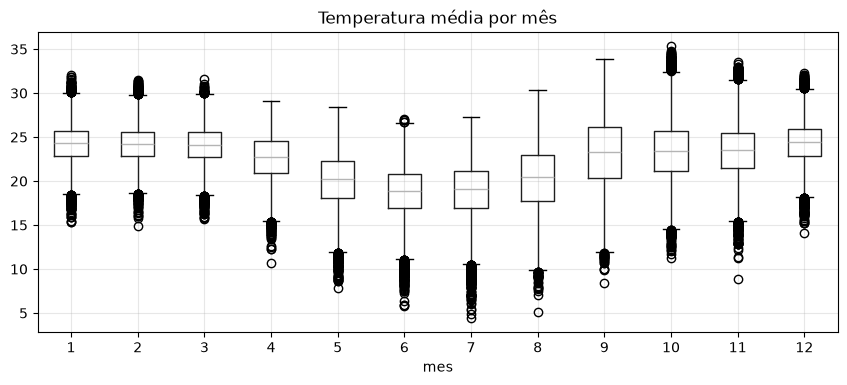

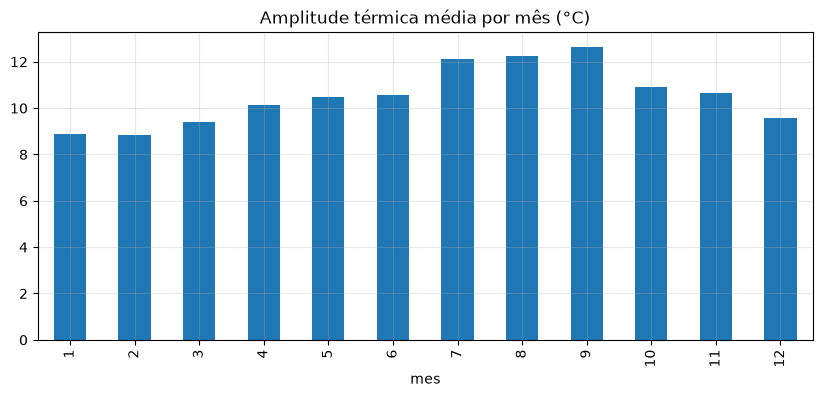

In [19]:
df.boxplot(column="temp_media_c", by="mes", figsize=(10, 4))
plt.suptitle("")
plt.title("Temperatura média por mês")
plt.show()

fig, ax = plt.subplots()
df.groupby("mes")["amplitude_c"].mean().plot(kind="bar", ax=ax, title="Amplitude térmica média por mês (°C)")
plt.show()

## 5. Relações entre variáveis

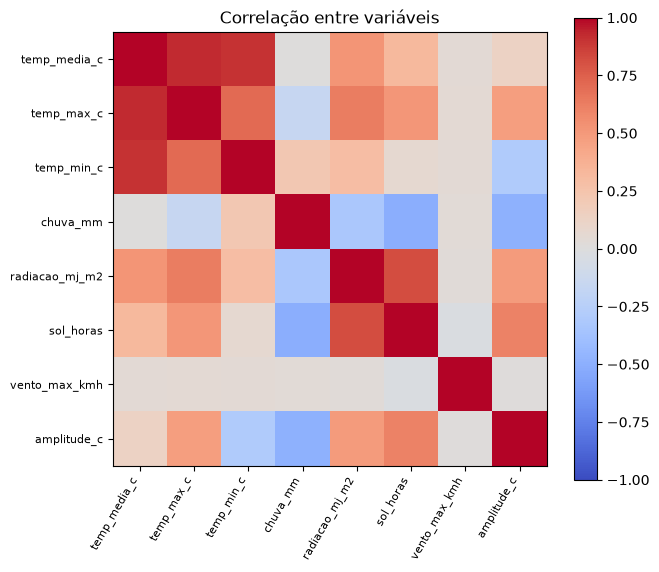

In [20]:
corr = df[VARS + ["amplitude_c"]].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.grid(False)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns, fontsize=8)
fig.colorbar(im)
ax.set_title("Correlação entre variáveis")
plt.show()

## 6. Autocorrelação

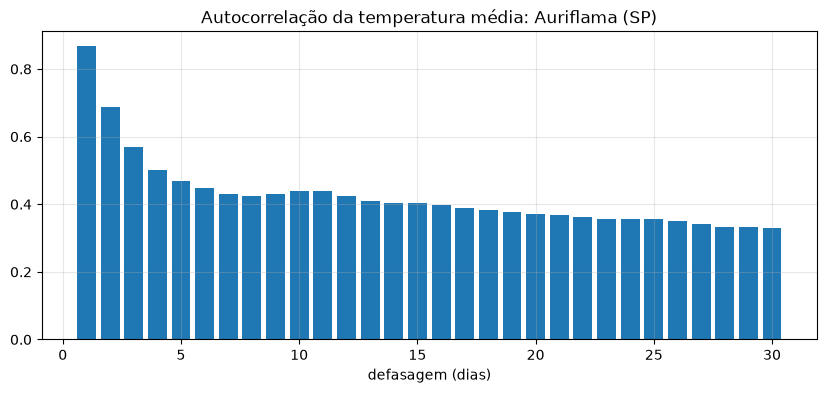

{1: 0.87, 2: 0.69, 7: 0.43, 14: 0.4, 365: 0.4}


In [21]:
serie = s.asfreq("D")   # uma linha por dia (dias faltando viram NaN)
lags = list(range(1, 31))
fig, ax = plt.subplots()
ax.bar(lags, [serie.autocorr(lag=l) for l in lags])
ax.set_title(f"Autocorrelação da temperatura média: {cidade}")
ax.set_xlabel("defasagem (dias)")
plt.show()
print({l: round(float(serie.autocorr(l)), 2) for l in (1, 2, 7, 14, 365)})

## 7. Comparação entre cidades

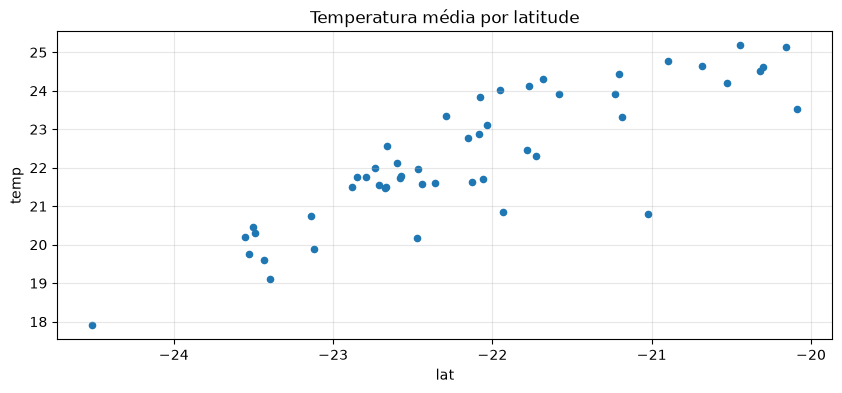

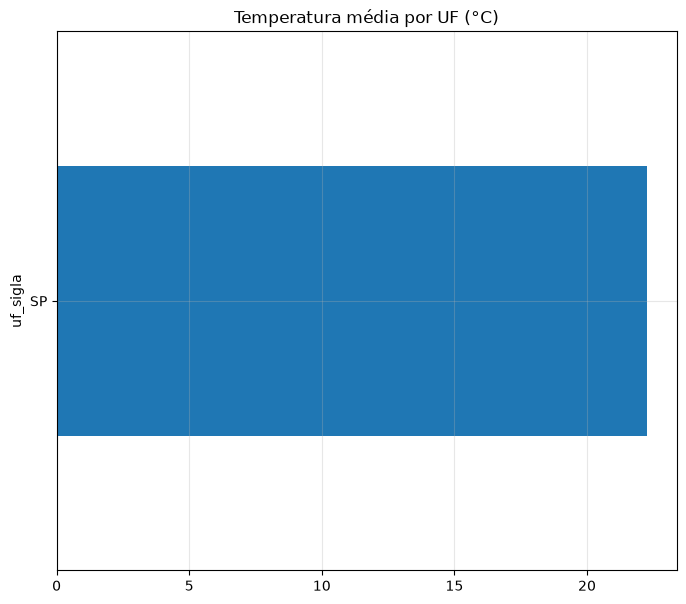

menor correlação entre duas cidades: 0.6


nome,Adamantina (SP),Adolfo (SP),Aguaí (SP),Agudos (SP),Alambari (SP),Alfredo Marcondes (SP),Altair (SP),Altinópolis (SP)
nome,,,,,,,,
Adamantina (SP),1.00,0.95,0.87,0.94,0.84,0.99,0.91,0.86
Adolfo (SP),0.95,1.00,0.95,0.96,0.88,0.94,0.96,0.93
Aguaí (SP),0.87,0.95,1.00,0.94,0.90,0.88,0.92,0.96
Agudos (SP),0.94,0.96,0.94,1.00,0.95,0.94,0.89,0.89
Alambari (SP),0.84,0.88,0.90,0.95,1.00,0.85,0.79,0.82
Alfredo Marcondes (SP),0.99,0.94,0.88,0.94,0.85,1.00,0.90,0.85
Altair (SP),0.91,0.96,0.92,0.89,0.79,0.90,1.00,0.96
Altinópolis (SP),0.86,0.93,0.96,0.89,0.82,0.85,0.96,1.00


In [22]:
por_cidade = df.groupby("nome").agg(temp=("temp_media_c", "mean"), lat=("lat", "first"), lng=("lng", "first"))
fig, ax = plt.subplots()
por_cidade.plot.scatter(x="lat", y="temp", ax=ax, title="Temperatura média por latitude")
plt.show()

fig, ax = plt.subplots(figsize=(8, 7))
df.groupby("uf_sigla")["temp_media_c"].mean().sort_values().plot(kind="barh", ax=ax, title="Temperatura média por UF (°C)")
plt.show()

pivo = df.pivot_table(index="data", columns="nome", values="temp_media_c")
corr_cidades = pivo.corr()
print("menor correlação entre duas cidades:", round(float(corr_cidades.min().min()), 2))
display(corr_cidades.round(2).iloc[:8, :8])

## 8. Modelos de referência

Antes de qualquer modelo, duas réguas simples que ele precisa vencer:

1. **Climatologia:** prever a média histórica daquele dia do ano (calculada só com o treino).
2. **Persistência:** prever a temperatura de ontem.

O teste usa o último ano de dados, separado por data.

In [23]:
corte = df["data"].max() - pd.Timedelta(days=365)
treino, teste = df[df["data"] <= corte], df[df["data"] > corte]

# Climatologia: média de cada cidade em cada dia do ano, só com o treino.
clim = treino.groupby(["ibge_id", "dia_do_ano"])["temp_media_c"].mean().rename("prev").reset_index()
av = teste.merge(clim, on=["ibge_id", "dia_do_ano"], how="left")
erro = av["temp_media_c"] - av["prev"]
print(f"Treino até {corte.date()} | teste: {len(teste)} linhas")
print(f"Climatologia: MAE {erro.abs().mean():.2f} °C | RMSE {np.sqrt((erro ** 2).mean()):.2f} °C")

# Persistência: temperatura de ontem (coluna da gold, vazia se faltar o dia anterior).
t = teste.dropna(subset=["temp_media_ontem_c"])
print(f"Persistência: MAE {(t['temp_media_c'] - t['temp_media_ontem_c']).abs().mean():.2f} °C")

Treino até 2025-10-18 | teste: 18250 linhas
Climatologia: MAE 1.94 °C | RMSE 2.49 °C
Persistência: MAE 1.23 °C


In [24]:
# Anomalia = temperatura menos a média do dia do ano. Mostra a "memória" além da sazonalidade.
df["anomalia"] = df["temp_media_c"] - df.groupby(["ibge_id", "dia_do_ano"])["temp_media_c"].transform("mean")
an = df[df["nome"] == cidade].set_index("data")["anomalia"].asfreq("D")
print({l: round(float(an.autocorr(l)), 2) for l in (1, 2, 3, 7)})

{1: 0.79, 2: 0.51, 3: 0.32, 7: 0.1}


## 9. Conclusões para a modelagem

*(a preencher depois de rodar com a carga completa)*

- Qualidade: o que precisou de tratamento (buracos, nulos, outliers).
- Variáveis candidatas e as que podem ficar de fora.
- Defasagens e médias móveis que valem como variáveis do modelo.
- Quanto o modelo precisa melhorar sobre a climatologia e a persistência para valer a pena.
- Como separar treino e teste (por data, sem embaralhar).